# Testing Model with Simulated Data
Evaluate Bernoulli model using simulated data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from gene_prevalence import BernoulliPrevalenceModel
from gene_prevalence.simulations import build_observed_data_matrix, \
    build_presence_absence_matrix, build_three_part_pi_vector

# instatiate random number generator with fixed seed for reproducibility
rng = np.random.default_rng(seed=9481)


### Well-Specified Model
Validate that model behaves as expected when simulation matches model assumptions

In [ ]:
# build simulated data that matches model assumptions

n_genomes = 1000
n_genes = 10000
genes_per_genome = 3000
n_core_genes = 800

# generate true pi values for all genes in the pangenome, with a three-part structure
pi_vector_true = build_three_part_pi_vector(
    pangenome_size=n_genes, 
    genes_per_genome=genes_per_genome, 
    n_core_genes=n_core_genes, 
    non_core_span=(0.05, 1.0)
    )

# build a presence-absence matrix based on the true pi values
presence_absence_matrix = build_presence_absence_matrix(
    pi_vector=pi_vector_true, 
    n_genomes=n_genomes, 
    n_genes=n_genes,
    rng=rng
    )

# generate completeness values for each genome, with a subset being complete
completeness_vector = pd.Series(
    np.clip(rng.uniform(low=0.05, high=1.1, size=n_genomes), 0, 1), 
    index=presence_absence_matrix.columns
    )

# build an observed data matrix by simulating the observation process with no 
# gene-specific biases and not enforcing completeness (i.e. simulating each gene 
# observation as an independent Bernoulli trial)

observed_data_matrix, observation_mask = build_observed_data_matrix(
    presence_absence_matrix=presence_absence_matrix,
    completeness_levels=completeness_vector,
    rng=rng, 
    return_observation_mask=True
    )

observed_data_matrix


,sim_genome_0,sim_genome_1,sim_genome_2,sim_genome_3,sim_genome_4,sim_genome_5,sim_genome_6,sim_genome_7,sim_genome_8,sim_genome_9,...,sim_genome_990,sim_genome_991,sim_genome_992,sim_genome_993,sim_genome_994,sim_genome_995,sim_genome_996,sim_genome_997,sim_genome_998,sim_genome_999
sim_gene_0,1,1,0,1,0,1,1,1,0,0,...,1,1,1,1,1,1,1,0,0,0
sim_gene_1,1,1,0,1,0,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
sim_gene_2,1,1,1,1,0,1,0,0,1,0,...,0,1,1,1,0,0,1,1,0,0
sim_gene_3,1,1,0,1,0,0,0,1,1,0,...,1,1,1,1,1,0,1,0,0,0
sim_gene_4,1,0,0,1,1,0,0,1,1,0,...,1,1,1,1,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sim_gene_9995,1,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
sim_gene_9996,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
sim_gene_9997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
sim_gene_9998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# fit the Bernoulli prevalence model to the simulated data



In [4]:
# fit the Bernoulli prevalence model to the complete and incomplete genomes independently

# set significance level for confidence intervals
alpha = 0.05

# separate out complete and incomplete genomes
sim_complete_df = observed_data_matrix.loc[:, completeness_vector == 1]
sim_incomplete_df = observed_data_matrix.loc[:, completeness_vector < 1]

# complete genomes
complete_model = BernoulliPrevalenceModel(
    data=sim_complete_df,
    lambdas=completeness_vector[completeness_vector == 1],
    clip_max=1.0,  # prevalence cannot exceed 1.0
)
pi_hat_complete = complete_model.estimate_prevalence()
ci_lower_complete, ci_upper_complete = complete_model.confidence_interval(
    alpha=alpha)

# incomplete genomes
incomplete_model = BernoulliPrevalenceModel(
    data=sim_incomplete_df,
    lambdas=completeness_vector[completeness_vector < 1],
    clip_max=1.0,  # prevalence cannot exceed 1.0
)
pi_hat_incomplete = incomplete_model.estimate_prevalence()
ci_lower_incomplete, ci_upper_incomplete = incomplete_model.confidence_interval(
    alpha=alpha)

# pull results together into a dataframe for comparison and visualization
estimate_df = pd.DataFrame(
    {
        "pi_true": pi_vector_true,
        "pi_hat_complete": pi_hat_complete, 
        "ci_upper_complete": ci_upper_complete,
        "ci_lower_complete": ci_lower_complete,
        "pi_hat_incomplete": pi_hat_incomplete,
        "ci_upper_incomplete": ci_upper_incomplete,
        "ci_lower_incomplete": ci_lower_incomplete,
    }
)

# # drop genes with prevalence of 0 in both complete and incomplete genomes
# estimate_df = estimate_df[~((estimate_df["pi_hat_complete"] == 0) & (estimate_df["pi_hat_incomplete"] == 0))]

# drop genes with prevalence of 1 in both complete and incomplete genomes
estimate_df = estimate_df[~((estimate_df["pi_hat_complete"] == 1) & (estimate_df["pi_hat_incomplete"] == 1))]


estimate_df

,pi_true,pi_hat_complete,ci_upper_complete,ci_lower_complete,pi_hat_incomplete,ci_upper_incomplete,ci_lower_incomplete
sim_gene_0,1.000000,1.000000,1.000000,1.000000,0.930240,1.000000,0.826391
sim_gene_3,1.000000,1.000000,1.000000,1.000000,0.959613,1.000000,0.854880
sim_gene_5,1.000000,1.000000,1.000000,1.000000,0.950393,1.000000,0.845931
sim_gene_7,1.000000,1.000000,1.000000,1.000000,0.969494,1.000000,0.864475
sim_gene_8,1.000000,1.000000,1.000000,1.000000,0.975299,1.000000,0.870115
...,...,...,...,...,...,...,...
sim_gene_9995,0.050103,0.051546,0.101747,0.001346,0.024446,0.044596,0.004296
sim_gene_9996,0.050077,0.041237,0.086381,0.000000,0.047918,0.076018,0.019817
sim_gene_9997,0.050051,0.051546,0.101747,0.001346,0.044879,0.072087,0.017670
sim_gene_9998,0.050026,0.061856,0.116548,0.007164,0.029687,0.051873,0.007502


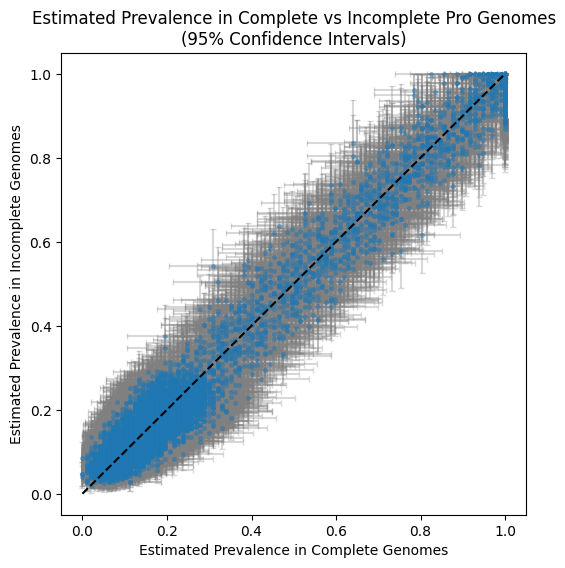

In [5]:
# plot the estimated prevalence in complete vs incomplete genomes
# along with confidence intervals as error bars

# make figure
plt.figure(figsize=(6, 6))
sns.scatterplot(
    data=estimate_df,
    x="pi_hat_complete",
    y="pi_hat_incomplete",
    # hue="mean_gene_copy",
    # style="mean_gene_copy",
    s=10,
    alpha=0.5,
    edgecolor=None,
    zorder=2
) 

# add error bars 
plt.errorbar(
    x=estimate_df["pi_hat_complete"],
    y=estimate_df["pi_hat_incomplete"],
    xerr=[estimate_df["pi_hat_complete"] - estimate_df["ci_lower_complete"], 
          estimate_df["ci_upper_complete"] - estimate_df["pi_hat_complete"]],
    yerr=[estimate_df["pi_hat_incomplete"] - estimate_df["ci_lower_incomplete"], 
          estimate_df["ci_upper_incomplete"] - estimate_df["pi_hat_incomplete"]],
    fmt="none",
    ecolor="gray",
    capsize=2,
    alpha=0.3,
    zorder=1,  # put error bars behind points
)

# add a dashed diagonal line for reference
plt.plot([0, 1], [0, 1], "--", color="black", zorder=3)

# set range limits
maximum = max(
    estimate_df["pi_hat_complete"].max(),
    estimate_df["pi_hat_incomplete"].max(),
)
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# add labels and title
plt.title(
    "Estimated Prevalence in Complete vs Incomplete Pro Genomes\n"
    f"({int((1-alpha)*100)}% Confidence Intervals)"
)
plt.xlabel("Estimated Prevalence in Complete Genomes")
plt.ylabel("Estimated Prevalence in Incomplete Genomes")
plt.show()

In [6]:
# what proportion of points fall within the confidence intervals of the other estimate?

true_in_complete = (
    (estimate_df["pi_true"] >= estimate_df["ci_lower_complete"]) &
    (estimate_df["pi_true"] <= estimate_df["ci_upper_complete"])
)

true_in_incomplete = (
    (estimate_df["pi_true"] >= estimate_df["ci_lower_incomplete"]) &
    (estimate_df["pi_true"] <= estimate_df["ci_upper_incomplete"])
)

within_ci_complete = (
    (estimate_df["pi_hat_incomplete"] >= estimate_df["ci_lower_complete"]) &
    (estimate_df["pi_hat_incomplete"] <= estimate_df["ci_upper_complete"])
)

within_ci_incomplete = (
    (estimate_df["pi_hat_complete"] >= estimate_df["ci_lower_incomplete"]) &
    (estimate_df["pi_hat_complete"] <= estimate_df["ci_upper_incomplete"])
)

print(f"Proportion of points where true prevalence is within complete CI: {true_in_complete.mean():.2f}")
print(f"Proportion of points where true prevalence is within incomplete CI: {true_in_incomplete.mean():.2f}")
print(f"Proportion of points where incomplete estimate is within complete CI: {within_ci_complete.mean():.2f}")
print(f"Proportion of points where complete estimate is within incomplete CI: {within_ci_incomplete.mean():.2f}")
print(f"Proportion of points where at least one estimate is within the other's CI: {(within_ci_complete | within_ci_incomplete).mean():.2f}")


Proportion of points where true prevalence is within complete CI: 0.96
Proportion of points where true prevalence is within incomplete CI: 0.97
Proportion of points where incomplete estimate is within complete CI: 0.89
Proportion of points where complete estimate is within incomplete CI: 0.78
Proportion of points where at least one estimate is within the other's CI: 0.93


In [7]:
# compile results at different significance levels for confidence intervals

alpha_values = np.linspace(0.01, 0.99, 99)

# save results for each alpha value in a list of dictionaries
results = []
for a in alpha_values:
    ci_lower_complete, ci_upper_complete = complete_model.confidence_interval(alpha=a)
    ci_lower_incomplete, ci_upper_incomplete = incomplete_model.confidence_interval(alpha=a)

    true_in_complete = (
        (estimate_df["pi_true"] >= ci_lower_complete.loc[estimate_df.index]) &
        (estimate_df["pi_true"] <= ci_upper_complete.loc[estimate_df.index])
    )

    true_in_incomplete = (
        (estimate_df["pi_true"] >= ci_lower_incomplete.loc[estimate_df.index]) &
        (estimate_df["pi_true"] <= ci_upper_incomplete.loc[estimate_df.index])
    )
    
    # identify incomplete estimates that fall within the complete confidence intervals
    within_ci_complete = (
        (estimate_df["pi_hat_incomplete"] >= ci_lower_complete.loc[estimate_df.index]) &
        (estimate_df["pi_hat_incomplete"] <= ci_upper_complete.loc[estimate_df.index])
    )

    # identify complete estimates that fall within the incomplete confidence intervals
    within_ci_incomplete = (
        (estimate_df["pi_hat_complete"] >= ci_lower_incomplete.loc[estimate_df.index]) &
        (estimate_df["pi_hat_complete"] <= ci_upper_incomplete.loc[estimate_df.index])
    )
    results.append({
        "significance_level": a,
        "confidence_level": 1 - a,
        "pi_true_within_ci_comp": true_in_complete.mean(),
        "pi_true_within_ci_inc": true_in_incomplete.mean(),
        "pi_inc_within_ci_comp": within_ci_complete.mean(),
        "pi_comp_within_ci_inc": within_ci_incomplete.mean(),
        "within_either_ci": (within_ci_complete | within_ci_incomplete).mean(),
        "within_both_ci": (within_ci_complete & within_ci_incomplete).mean(),
    })

ci_results_df = pd.DataFrame(results)
ci_results_df

,significance_level,confidence_level,pi_true_within_ci_comp,pi_true_within_ci_inc,pi_inc_within_ci_comp,pi_comp_within_ci_inc,within_either_ci,within_both_ci
0,0.01,0.99,0.996974,1.000000,0.954612,0.990714,0.999687,0.945639
1,0.02,0.98,0.993322,0.999270,0.945430,0.945639,0.991653,0.899416
2,0.03,0.97,0.985601,0.996348,0.928005,0.883452,0.975897,0.835559
3,0.04,0.96,0.976106,0.986644,0.907137,0.827421,0.955447,0.779111
4,0.05,0.95,0.960872,0.971411,0.885225,0.779633,0.934161,0.730697
...,...,...,...,...,...,...,...,...
94,0.95,0.05,0.412563,0.385121,0.308118,0.230175,0.330655,0.207638
95,0.96,0.04,0.410580,0.383347,0.306866,0.229654,0.329403,0.207116
96,0.97,0.03,0.408285,0.381469,0.304257,0.228088,0.326795,0.205551
97,0.98,0.02,0.406824,0.378965,0.302588,0.227149,0.324917,0.204821


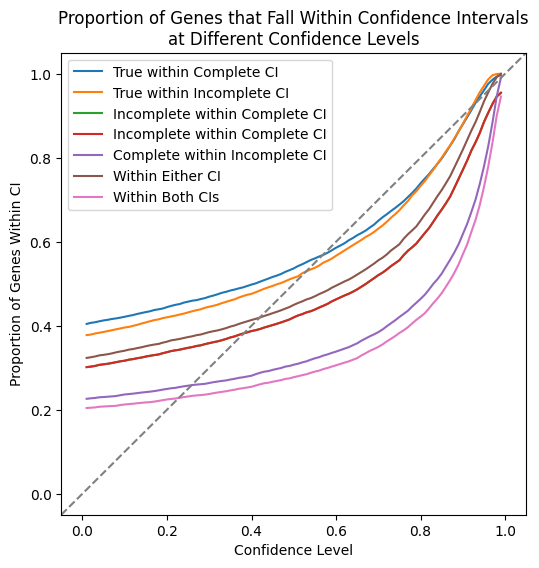

In [8]:
# plot the confidence interval results

plt.figure(figsize=(6, 6))
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="pi_true_within_ci_comp", label="True within Complete CI")
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="pi_true_within_ci_inc", label="True within Incomplete CI")
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="pi_inc_within_ci_comp", label="Incomplete within Complete CI")
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="pi_inc_within_ci_comp", label="Incomplete within Complete CI")
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="pi_comp_within_ci_inc", label="Complete within Incomplete CI")
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="within_either_ci", label="Within Either CI")
sns.lineplot(data=ci_results_df, x="confidence_level", 
             y="within_both_ci", label="Within Both CIs")
plt.xlabel("Confidence Level")
plt.ylabel("Proportion of Genes Within CI")
plt.title(
    "Proportion of Genes that Fall Within Confidence Intervals\n"
    "at Different Confidence Levels")
plt.legend()

# set limits to focus on the range of interest
range_min = -0.05
range_max = 1.05
plt.xlim(range_min, range_max)
plt.ylim(range_min, range_max)

# reference line where proportion = confidence level
plt.plot(
    [range_min, range_max], 
    [range_min, range_max], 
    "--", color="gray")

plt.show()